# Housing typologies in King County (WA): an unsupervised reading of the housing stock

**Team:** Karthikeyan Saravanan, Emmanuel Marquez, Bars Babila, Samiha Abeda Nur
**Course:** AI Methods I – Day 3: Unsupervised learning (IAAC MaAI 2026/27)

# 0. Introduction and problem definition

## 0.1 Use case

There is no target today, so the question comes first. On Day 2 we predicted the price of a house. Here we ask a different one: **which types of house make up the King County housing stock, and where are they?**

| Question from the brief | Our answer |
|---|---|
| **Who uses the groups, and for what?** | A county housing or planning department that designs programmes for the existing stock (retrofit, ageing-in-place, density incentives) and cannot write one policy for every house. |
| **Which features define "similar"?** | The **physical building**: size, plot, rooms, storeys, construction quality, age, basement. Two houses are similar if they are similar *as buildings*, wherever they are and whatever they sold for. |
| **What would make a group useful?** | We can **name** it as a recognisable house type, and a planner can **act** on it: the group has a clear size, age and location, so a programme can be aimed at it. |

Keeping price and location out of the clustering is the key decision. If they were in, the groups would partly restate what we fed in. Left out, they become an **independent check**: if purely physical groups also differ in price and geography, the groups mean something beyond their own definition.

## 0.2 Setup

The notebook lives in `notebook/`, so every other folder is **one level up**: all paths are relative and start from `Path("..")`. A fixed `RANDOM_STATE` is used wherever randomness is involved, so a re-run gives the same result.

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install -r ../requirements.txt

In [2]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
warnings.filterwarnings("ignore", message="IProgress not found")   # raised by a progress bar inside umap
import umap
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

In [3]:
# --- Folders (the notebook lives in notebook/, the rest is one level up) ---
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATASET_DIR = Path("..") / "dataset"   # the clustered dataset we publish
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, DATASET_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings ----------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

# One blue for magnitude, blue-to-orange around a neutral for signed values
BLUE = "#2a78d6"
SEQUENTIAL = LinearSegmentedColormap.from_list("seq_blue", ["#86b6ef", "#2a78d6", "#104281", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div_blue_orange", ["#104281", "#2a78d6", "#f0efec", "#eb6834", "#a8401a"])

# The same seed everywhere
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## 0.3 Load the data

We reuse the **cleaned dataset from our Day 2 assignment**, so no second cleaning notebook is needed. The original is [House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction) on Kaggle (licence: CC0, public domain), with the sales of homes from May 2014 to May 2015.

If the file is not yet in `data/`, the cell downloads it from our public Day 2 repository and stores it there.

In [4]:
CLEAN_URL = "https://raw.githubusercontent.com/iaac-maai/2-day2-assignment/main/data/kc_houses_data_clean.csv"
CLEAN_PATH = DATA_DIR / "kc_houses_data_clean.csv"

if not CLEAN_PATH.exists():
    pd.read_csv(CLEAN_URL).to_csv(CLEAN_PATH, index=False)
    print(f"Downloaded to {CLEAN_PATH}")

sales = pd.read_csv(CLEAN_PATH, parse_dates=["date"])
print(f"{sales.shape[0]:,} rows, {sales.shape[1]} columns")
print(f"Sales from {sales['date'].min():%Y-%m-%d} to {sales['date'].max():%Y-%m-%d}, {sales['zipcode'].nunique()} ZIP codes")
print(f"Missing values: {sales.isna().sum().sum()}, duplicated rows: {sales.duplicated().sum()}")
sales.head()

20,703 rows, 19 columns
Sales from 2014-05-02 to 2015-05-27, 70 ZIP codes
Missing values: 0, duplicated rows: 0


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,"221,900.000",3,1.000,1180,5650,1.000,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650
1,6414100192,2014-12-09,"538,000.000",3,2.250,2570,7242,2.000,3,7,2170,400,1951,1991,98125,47.721,-122.319,1690,7639
2,5631500400,2015-02-25,"180,000.000",2,1.000,770,10000,1.000,3,6,770,0,1933,0,98028,47.738,-122.233,2720,8062
3,2487200875,2014-12-09,"604,000.000",4,3.000,1960,5000,1.000,5,7,1050,910,1965,0,98136,47.521,-122.393,1360,5000
4,1954400510,2015-02-18,"510,000.000",3,2.000,1680,8080,1.000,3,8,1680,0,1987,0,98074,47.617,-122.045,1800,7503


## 0.4 Unit of analysis

The file has **one row per sale**, but our question is about the **stock of buildings**: a house sold twice in the year must not count as two houses. The next cell checks how many repeat sales there are and whether the building changed between them.

In [5]:
PHYSICAL_COLUMNS = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
                    "condition", "grade", "yr_built", "yr_renovated"]

repeat_sales = sales[sales.duplicated("id", keep=False)]
changed = (repeat_sales.groupby("id")[PHYSICAL_COLUMNS].nunique() > 1).any(axis=1).sum()
print(f"Houses sold more than once: {repeat_sales['id'].nunique()} ({len(repeat_sales)} rows)")
print(f"Of those, houses whose physical columns changed between sales: {changed}")

# One row = one house: keep the most recent sale of each one
houses = (sales.sort_values("date")
               .drop_duplicates("id", keep="last")
               .sort_index()
               .reset_index(drop=True))
print(f"Rows removed: {len(sales) - len(houses)}. Houses kept: {len(houses):,}")

Houses sold more than once: 148 (296 rows)
Of those, houses whose physical columns changed between sales: 0
Rows removed: 148. Houses kept: 20,555


**One row = one house.** 148 houses were sold twice, and none of them changed physically between sales (no difference in any of the 9 physical columns), so the duplicates add no information about the stock and would count those buildings twice. We keep the most recent sale of each, going from 20,703 sales to **20,555 houses**. No aggregation is needed beyond this. For those 148 houses, `price` and `date` refer to the latest sale.

# 1. Features and preprocessing

The columns we choose **are** the definition of "similar", so this is the most consequential decision of the notebook.

## 1.1 Engineered features

First we derive new columns. Some will be clustered on; the others are for interpretation. All of them go into the final dataset.

| New column | Definition | Why |
|---|---|---|
| `sale_year`, `sale_month` | From `date` | Calendar context |
| `house_age` | `sale_year − yr_built`, floored at 0 | Age at sale. A few homes were sold before completion, which would give −1 |
| `renovated` | 1 if `yr_renovated > 0` | The original column mixes a year with 0 = "never" |
| `years_since_work` | `sale_year` minus the latest of `yr_built` and `yr_renovated` | The effective age of the fabric, relevant for retrofit |
| `basement_share` | `sqft_basement / sqft_living` | How much of the house is below ground, independent of size |
| `lot_coverage` | `(sqft_above / floors) / sqft_lot` | Approximate footprint over plot: urban vs suburban form |
| `living_vs_neighbours` | `sqft_living / sqft_living15` | Is the house big *for its street*? |
| `price_per_sqft` | `price / sqft_living` | Comparable price level |
| `dist_downtown_km` | Great-circle distance to downtown Seattle (47.6062, −122.3321) | A summary of location that a planner can read |

In [6]:
DOWNTOWN_LAT, DOWNTOWN_LONG = 47.6062, -122.3321


def distance_km(lat, long, lat0, long0):
    # Great-circle (haversine) distance in kilometres
    lat, long, lat0, long0 = map(np.radians, [lat, long, lat0, long0])
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((long - long0) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


houses["sale_year"] = houses["date"].dt.year
houses["sale_month"] = houses["date"].dt.month
houses["house_age"] = (houses["sale_year"] - houses["yr_built"]).clip(lower=0)
houses["renovated"] = (houses["yr_renovated"] > 0).astype(int)
houses["years_since_work"] = (houses["sale_year"] - houses[["yr_built", "yr_renovated"]].max(axis=1)).clip(lower=0)
houses["basement_share"] = houses["sqft_basement"] / houses["sqft_living"]
houses["lot_coverage"] = (houses["sqft_above"] / houses["floors"]) / houses["sqft_lot"]
houses["living_vs_neighbours"] = houses["sqft_living"] / houses["sqft_living15"]
houses["price_per_sqft"] = houses["price"] / houses["sqft_living"]
houses["dist_downtown_km"] = distance_km(houses["lat"], houses["long"], DOWNTOWN_LAT, DOWNTOWN_LONG)

print(f"Homes sold before completion (age floored at 0): {(houses['yr_built'] > houses['sale_year']).sum()}")
print(f"Rows with lot_coverage above 1 (the estimate is rough): {(houses['lot_coverage'] > 1).sum()}")
houses[["house_age", "renovated", "years_since_work", "basement_share", "lot_coverage",
        "living_vs_neighbours", "price_per_sqft", "dist_downtown_km"]].describe().T

Homes sold before completion (age floored at 0): 11
Rows with lot_coverage above 1 (the estimate is rough): 4


,count,mean,std,min,25%,50%,75%,max
house_age,"20,555.000",42.763,29.159,0.000,17.000,39.000,62.000,115.000
renovated,"20,555.000",0.041,0.199,0.000,0.000,0.000,0.000,1.000
years_since_work,"20,555.000",40.429,28.566,0.000,15.000,37.000,59.000,115.000
basement_share,"20,555.000",0.125,0.172,0.000,0.000,0.000,0.276,0.667
lot_coverage,"20,555.000",0.179,0.104,0.001,0.115,0.163,0.228,3.103
living_vs_neighbours,"20,555.000",1.052,0.302,0.248,0.888,1.000,1.156,6.000
price_per_sqft,"20,555.000",260.931,103.415,87.713,182.927,243.976,314.959,810.139
dist_downtown_km,"20,555.000",18.570,10.628,0.983,9.869,16.667,25.380,76.979


## 1.2 Which features we cluster on, and which we keep aside

| Role | Columns | Reason |
|---|---|---|
| **Clustered on** | `sqft_living`, `sqft_lot`, `bedrooms`, `bathrooms`, `floors`, `grade`, `house_age`, `basement_share` | They describe the building and its plot: size, layout, form, construction quality, age |
| **Aside: market** | `price`, `price_per_sqft` | Clustering on price would produce price bands. Our Day 2 model already covers price |
| **Aside: location** | `lat`, `long`, `zipcode`, `dist_downtown_km` | Clustering on location would produce a map of districts, not house types. One-hot `zipcode` would also add 70 columns that swamp the 8 physical ones |
| **Aside: context** | `sqft_living15`, `sqft_lot15`, `living_vs_neighbours`, `lot_coverage` | They describe the street, or are derived from columns already in the list |
| **Aside: state** | `condition`, `renovated`, `yr_renovated`, `years_since_work` | They describe the *state* of a house, not its *type*, and are exactly what a retrofit programme wants to compare across types |
| **Dropped as redundant** | `sqft_above`, `sqft_basement`, `yr_built` | `sqft_above + sqft_basement = sqft_living` in every row; the split is captured by `basement_share`, and `yr_built` by `house_age` |

`grade` and `floors` are ordinal scales with meaningful steps, so we treat them as numbers rather than one-hot encoding them. No categorical column is clustered on.

In [7]:
CLUSTER_FEATURES = ["sqft_living", "sqft_lot", "bedrooms", "bathrooms",
                    "floors", "grade", "house_age", "basement_share"]
ASIDE_FEATURES = ["price", "price_per_sqft", "lat", "long", "zipcode", "dist_downtown_km",
                  "sqft_living15", "sqft_lot15", "living_vs_neighbours", "lot_coverage",
                  "condition", "renovated", "yr_renovated", "years_since_work"]

print("Exact check of the redundancy:", (houses["sqft_above"] + houses["sqft_basement"] == houses["sqft_living"]).all())
X = houses[CLUSTER_FEATURES]
X.describe().T

Exact check of the redundancy: True


,count,mean,std,min,25%,50%,75%,max
sqft_living,"20,555.000","2,054.568",800.300,720.000,"1,450.000","1,920.000","2,520.000","4,970.000"
sqft_lot,"20,555.000","14,676.586","39,167.098",520.000,"5,025.000","7,575.000","10,500.000","1,651,359.000"
bedrooms,"20,555.000",3.380,0.835,2.000,3.000,3.000,4.000,6.000
bathrooms,"20,555.000",2.110,0.715,0.500,1.750,2.250,2.500,5.250
floors,"20,555.000",1.498,0.540,1.000,1.000,1.500,2.000,3.500
grade,"20,555.000",7.649,1.085,4.000,7.000,7.000,8.000,13.000
house_age,"20,555.000",42.763,29.159,0.000,17.000,39.000,62.000,115.000
basement_share,"20,555.000",0.125,0.172,0.000,0.000,0.000,0.276,0.667


## 1.3 Skewed columns

K-Means, PCA and t-SNE all work with distances or variances, so a column with a long tail lets a few extreme rows dominate. We compare the skewness of each feature with and without a log transform. Skewness near 0 means symmetric; above 1 is usually considered strong.

In [8]:
skew_check = pd.DataFrame({
    "skew_raw": X.skew(),
    "skew_log10": np.log10(X.where(X > 0)).skew(),
    "share_of_zeros": (X == 0).mean(),
}).round(2)
skew_check

,skew_raw,skew_log10,share_of_zeros
sqft_living,0.800,-0.070,0.000
sqft_lot,13.010,0.950,0.000
bedrooms,0.410,-0.290,0.000
bathrooms,0.200,-0.610,0.000
floors,0.600,0.260,0.000
grade,0.730,0.260,0.000
house_age,0.490,-1.190,0.020
basement_share,0.900,-1.450,0.610


**Decision: log10 for `sqft_living` and `sqft_lot` only.**

- `sqft_lot` is the real problem: its skew of 13.01 falls to 0.95 with the log. The median plot is 7,575 sqft and the largest is 1,651,359 sqft.
- `sqft_living` is only mildly skewed (0.80), but the log makes it almost symmetric (−0.07), and an area is naturally read in proportions. We also used log10 on Day 2.
- The other columns are already below 1, and the log would make `house_age` and `basement_share` worse (−1.19 and −1.45). It is not even defined for their zeros: **61% of the houses have no basement**, which makes `basement_share` a column with a big spike at 0. We keep it in mind when reading the maps.

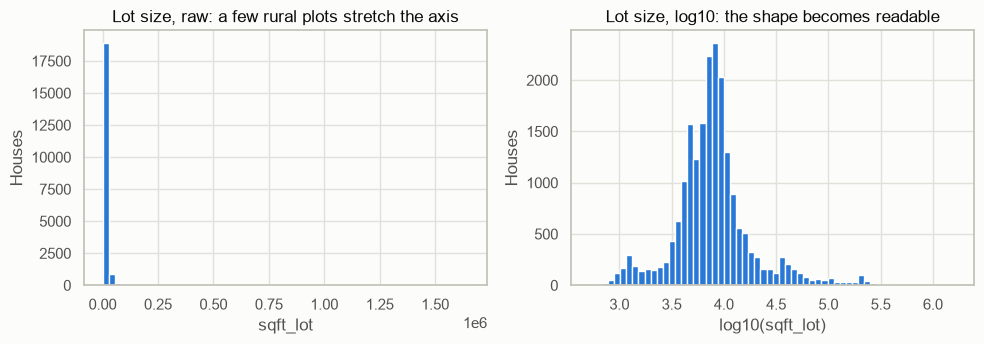

In [9]:
LOG_FEATURES = ["sqft_living", "sqft_lot"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(X["sqft_lot"], bins=60, color=BLUE)
axes[0].set(title="Lot size, raw: a few rural plots stretch the axis", xlabel="sqft_lot", ylabel="Houses")
axes[1].hist(np.log10(X["sqft_lot"]), bins=60, color=BLUE)
axes[1].set(title="Lot size, log10: the shape becomes readable", xlabel="log10(sqft_lot)", ylabel="Houses")
plt.tight_layout()
plt.show()

## 1.4 Scaling inside a `Pipeline`

The features have different units (square feet, years, a 4–13 grade, a share), so they do **not** share a scale: without scaling, `sqft_lot` would decide every distance. We use a `StandardScaler` (mean 0, standard deviation 1), which gives every feature the same weight.

The log and the scaler go in one `Pipeline`, called `preprocess`. The whole recipe then travels together: a new house passed through it gets exactly the same transformation, which section 6 needs. It takes the **original units** as input, and outputs a table with the same 8 columns.

In [10]:
log_areas = ColumnTransformer(
    [("log10", FunctionTransformer(np.log10, feature_names_out="one-to-one"), LOG_FEATURES)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocess = Pipeline([("log_areas", log_areas), ("scale", StandardScaler())]).set_output(transform="pandas")

X_scaled = preprocess.fit_transform(X)
print(f"Scaled matrix: {X_scaled.shape[0]:,} houses x {X_scaled.shape[1]} features")
X_scaled.describe().loc[["mean", "std"]].round(3)

Scaled matrix: 20,555 houses x 8 features


,sqft_living,sqft_lot,bedrooms,bathrooms,floors,grade,house_age,basement_share
mean,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


Do the features overlap? Correlated columns count the same idea twice in every distance. The heatmap below shows how much they share, and is also the first hint of what PCA will find.

Figure saved to ../figures/00_feature_correlations.png


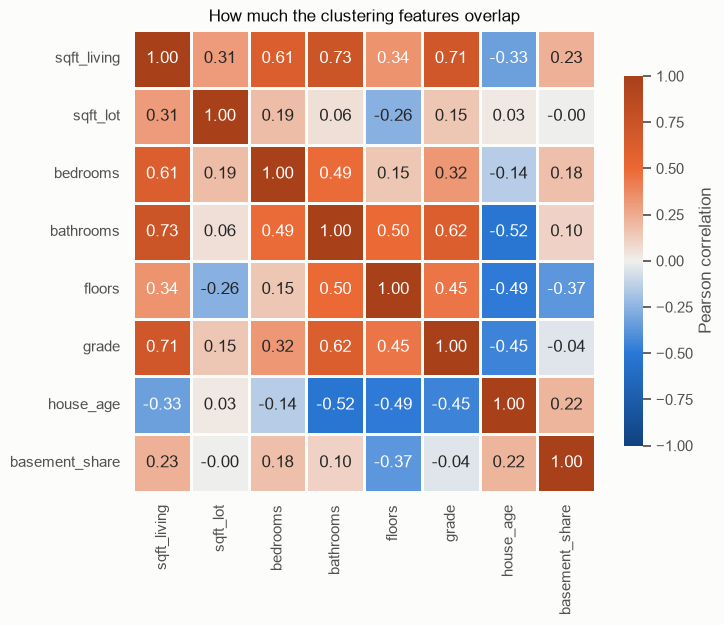

sqft_living  bathrooms    0.730
             grade        0.710
bathrooms    grade        0.620
sqft_living  bedrooms     0.610
bathrooms    house_age   -0.520
             floors       0.500
dtype: float64

In [11]:
corr = X_scaled.corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, square=True,
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set_title("How much the clustering features overlap")
save_fig("00_feature_correlations")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
upper.head(6).round(2)

**Reading.** The strongest pairs are `sqft_living`–`bathrooms` (0.73), `sqft_living`–`grade` (0.71) and `bathrooms`–`grade` (0.62): bigger houses have more bathrooms and better construction. These columns share one idea, "how much house", but none is close to a duplicate (nothing above 0.9), and each adds something an architect cares about, so we keep them all. The consequence is that size will weigh more than any other idea in the distances. `bathrooms`–`house_age` (−0.52) adds a second theme: older houses have fewer bathrooms.

# 2. Dimensionality reduction

We have 8 scaled features and cannot look at 8 dimensions. Two complementary tools:

- **PCA** is linear and global. Its axes can be read, and it tells us how many real dimensions the data has.
- **t-SNE and UMAP** are non-linear and local. They draw neighbourhoods in 2D, but **the size of a blob and the distance between blobs carry no meaning**.

To test whether what we see is real, we colour the maps with variables the methods **never saw**: price and distance to downtown.

## 2.1 PCA: how many real dimensions?

In [12]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
pc_names = [f"PC{i + 1}" for i in range(pca_full.n_components_)]

explained = pd.DataFrame({
    "eigenvalue": pca_full.explained_variance_,
    "variance_share": pca_full.explained_variance_ratio_,
    "cumulative": pca_full.explained_variance_ratio_.cumsum(),
}, index=pc_names)
explained.round(3)

,eigenvalue,variance_share,cumulative
PC1,3.374,0.422,0.422
PC2,1.681,0.210,0.632
PC3,1.025,0.128,0.760
PC4,0.660,0.082,0.842
PC5,0.530,0.066,0.909
PC6,0.336,0.042,0.951
PC7,0.251,0.031,0.982
PC8,0.145,0.018,1.000


Figure saved to ../figures/01_pca_explained_variance.png


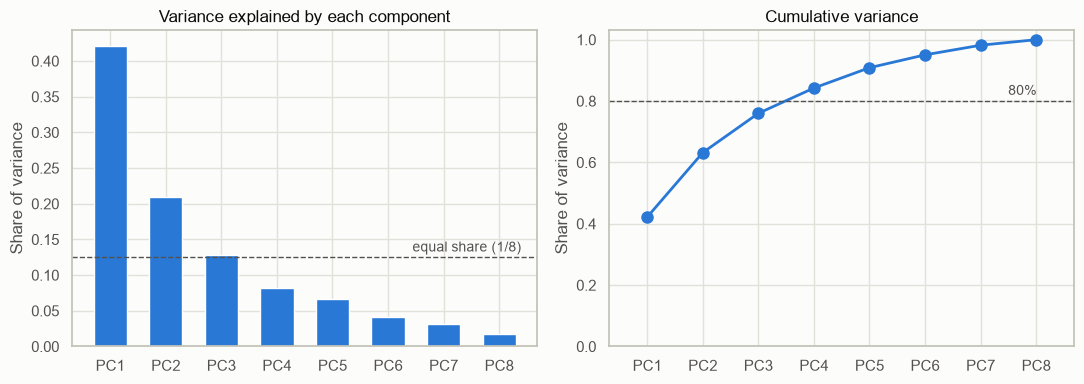

Components above an equal share (eigenvalue > 1): 3
Components for 80% of the variance: 4; for 90%: 5
First two components (the PCA map): 63.2%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
axes[0].bar(pc_names, explained["variance_share"], color=BLUE, width=0.6)
axes[0].axhline(1 / len(pc_names), color="#52514e", linestyle="--", linewidth=1)
axes[0].text(7.4, 1 / len(pc_names) + 0.008, "equal share (1/8)", ha="right", color="#52514e", fontsize=10)
axes[0].set(title="Variance explained by each component", ylabel="Share of variance")
axes[1].plot(pc_names, explained["cumulative"], color=BLUE, linewidth=2, marker="o", markersize=8)
axes[1].axhline(0.8, color="#52514e", linestyle="--", linewidth=1)
axes[1].text(7, 0.82, "80%", ha="right", color="#52514e", fontsize=10)
axes[1].set(title="Cumulative variance", ylabel="Share of variance", ylim=(0, 1.03))
plt.tight_layout()
save_fig("01_pca_explained_variance")
plt.show()

components_80 = int((explained["cumulative"] >= 0.80).idxmax().removeprefix("PC"))
components_90 = int((explained["cumulative"] >= 0.90).idxmax().removeprefix("PC"))
print(f"Components above an equal share (eigenvalue > 1): {(explained['eigenvalue'] > 1).sum()}")
print(f"Components for 80% of the variance: {components_80}; for 90%: {components_90}")
print(f"First two components (the PCA map): {explained['cumulative'].iloc[1]:.1%}")

**How many real dimensions?** About **3 to 4, out of 8.**

- PC1 alone takes 42.2% and PC2 21.0%, so the PCA map shows 63.2% of the variance. That is useful, but more than a third of the information is not on it.
- Three components have an eigenvalue above 1 (PC3 only just, at 1.03) and together reach 76.0%. Four reach 84.2%, five reach 90.9%.
- There is no sharp elbow after PC3: the variance decreases gradually. The features are related, but the data is not a thin 2D sheet.

So the 2D maps are a simplification, and clustering should use the 8 scaled features rather than the map coordinates.

## 2.2 Reading the loadings

A **loading** is the weight of a feature in a component. A large positive or negative value means that the feature drives the axis; the sign only tells us which end is which. We read the components that carry real variance.

Figure saved to ../figures/02_pca_loadings.png


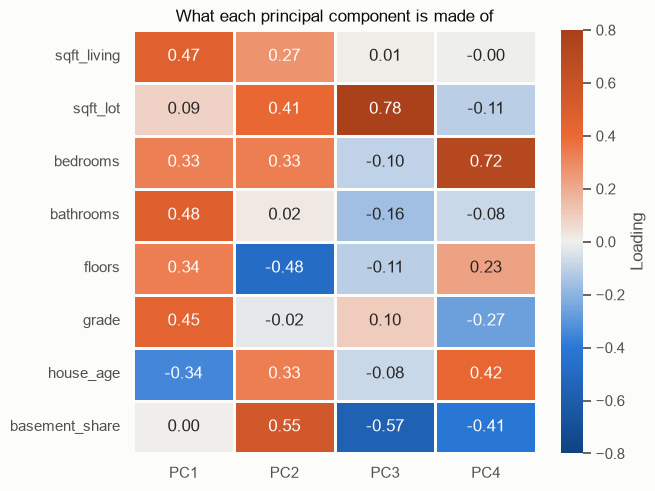

In [14]:
N_READ = 4
loadings = pd.DataFrame(pca_full.components_[:N_READ].T, index=X_scaled.columns, columns=pc_names[:N_READ])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap=DIVERGING, center=0, vmin=-0.8, vmax=0.8,
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "Loading"}, ax=ax)
ax.set_title("What each principal component is made of")
save_fig("02_pca_loadings")
plt.show()

**Reading of the components** (the sign of a component is arbitrary, the contrast is what matters):

| Component | Variance | Main loadings | Meaning |
|---|---|---|---|
| **PC1** | 42.2% | `bathrooms` +0.48, `sqft_living` +0.47, `grade` +0.45, `floors` +0.34, `bedrooms` +0.33, `house_age` −0.34 | **"How much house".** Large, well-built, newer houses at the positive end; small, plain, older ones at the negative end |
| **PC2** | 21.0% | `basement_share` +0.55, `floors` −0.48, `sqft_lot` +0.41, `bedrooms` +0.33, `house_age` +0.33 | **Building form.** Older low-rise houses with a basement on bigger plots, against newer multi-storey houses without a basement |
| **PC3** | 12.8% | `sqft_lot` +0.78, `basement_share` −0.57 | **Plot.** A large plot against a house that uses its basement |
| **PC4** | 8.2% | `bedrooms` +0.72, `house_age` +0.42, `basement_share` −0.41 | **Rooms for the size.** Many bedrooms, in older houses. It is below the equal share, so we read it with less confidence |

`sqft_living` loads almost nothing on PC3 and PC4, so size is really concentrated in PC1. Form (PC2) is independent of it by construction: two houses of the same size can sit at opposite ends of PC2.

Loadings describe what an axis is made of. To see what it **means** for the housing stock, we correlate the first components with the variables kept aside. Spearman correlation is used because prices and distances are skewed.

In [15]:
pc_scores = pd.DataFrame(pca_full.transform(X_scaled)[:, :N_READ], columns=pc_names[:N_READ])
check_columns = ["price", "price_per_sqft", "dist_downtown_km", "lat", "long", "lot_coverage",
                 "living_vs_neighbours", "condition", "years_since_work"]

pc_vs_aside = pd.concat([pc_scores, houses[check_columns]], axis=1).corr(method="spearman").loc[check_columns, pc_scores.columns]
pc_vs_aside.round(2)

,PC1,PC2,PC3,PC4
price,0.540,0.190,-0.110,-0.030
price_per_sqft,-0.170,-0.080,-0.100,-0.040
dist_downtown_km,0.210,-0.070,0.480,-0.070
lat,-0.010,0.050,-0.160,-0.020
long,0.340,-0.070,0.390,-0.060
lot_coverage,0.060,-0.360,-0.620,0.070
living_vs_neighbours,0.420,0.290,-0.280,0.080
condition,-0.230,0.320,-0.010,0.090
years_since_work,-0.660,0.460,0.020,0.220


**Reading.** Only the columns PCA did not see are a fair test, and the result is mixed:

- **Price is linked to PC1** (Spearman 0.54): "how much house" is partly what buyers pay for. This is a real link, as price was never used.
- **Price per square foot is not** (−0.17 at most): what the market pays per unit of area does not follow the physical type. It is probably driven by location, which we left out on purpose.
- **PC3 is the suburban axis:** it follows `dist_downtown_km` (0.48), `long` (0.39, towards the east) and, negatively, `lot_coverage` (−0.62). Big plots are far from the centre. Note that `lot_coverage` is computed from `sqft_lot`, so that one correlation is partly built in; distance and longitude are independent.
- **Latitude says nothing** (0.16 at most in absolute value): the physical type varies from centre to periphery, not from north to south.
- `condition` shows only modest links (−0.23 on PC1, 0.32 on PC2). `years_since_work` looks strong (−0.66, 0.46), but it is nearly the same thing as `house_age`, which is an input, so **this is not independent evidence**.

## 2.3 The PCA map

We keep the first two components as the PCA map. Each dot is a house. The colours are variables **PCA did not see**.

Figure saved to ../figures/03_pca_map.png


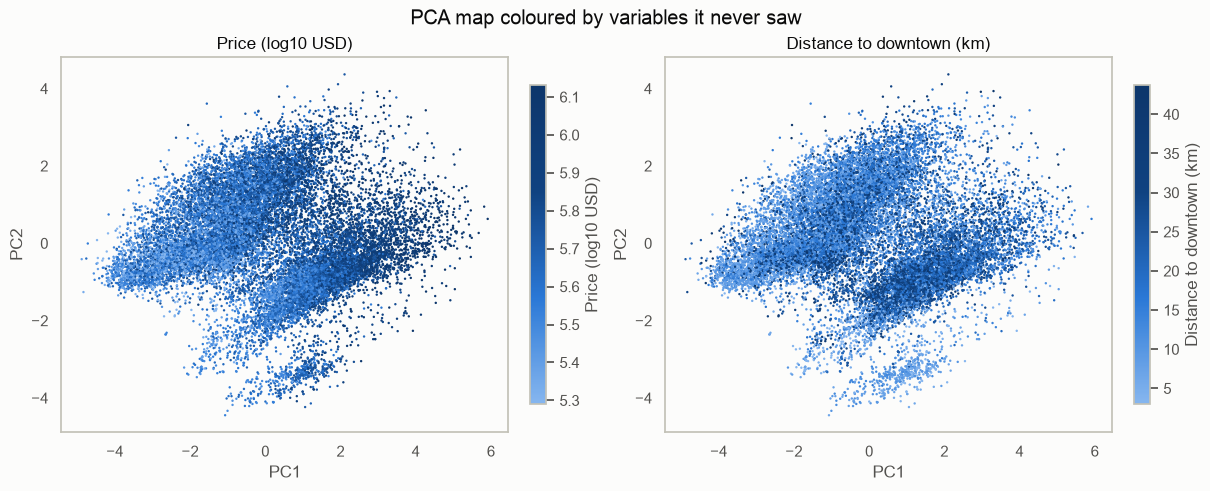

In [16]:
pca_map = PCA(n_components=2, random_state=RANDOM_STATE)
pca_xy = pca_map.fit_transform(X_scaled)

# Drawing order is shuffled so high values do not always end up on top
draw_order = np.random.default_rng(RANDOM_STATE).permutation(len(houses))


def draw_map(ax, xy, values, title, xlabel, ylabel, vmin=None, vmax=None):
    # One map: a dot per house, coloured by a single variable
    points = ax.scatter(xy[draw_order, 0], xy[draw_order, 1], c=values[draw_order], s=3, linewidths=0,
                        cmap=SEQUENTIAL, vmin=vmin, vmax=vmax, rasterized=True)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(False)
    return points


# Colour variables: the 2nd-98th percentiles keep a few extremes from flattening the scale
COLOURS = {
    "Price (log10 USD)": np.log10(houses["price"]).to_numpy(),
    "Distance to downtown (km)": houses["dist_downtown_km"].to_numpy(),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, (label, values) in zip(axes, COLOURS.items()):
    low, high = np.percentile(values, [2, 98])
    points = draw_map(ax, pca_xy, values, label, "PC1", "PC2", low, high)
    fig.colorbar(points, ax=ax, label=label, shrink=0.85)
fig.suptitle("PCA map coloured by variables it never saw")
save_fig("03_pca_map")
plt.show()

The map has a thin separate tail at the bottom (PC2 below −2.5). This is not a clustering, only a check of who those houses are, compared with everything else.

In [17]:
in_tail = pca_xy[:, 1] < -2.5
tail_columns = ["sqft_living", "sqft_lot", "floors", "grade", "house_age", "basement_share",
                "price", "dist_downtown_km", "lot_coverage"]
print(f"Houses in the tail: {in_tail.sum()} ({in_tail.mean():.1%})")
pd.DataFrame({
    "tail_median": houses.loc[in_tail, tail_columns].median(),
    "rest_median": houses.loc[~in_tail, tail_columns].median(),
})

Houses in the tail: 697 (3.4%)


,tail_median,rest_median
sqft_living,"1,340.000","1,954.000"
sqft_lot,"1,250.000","7,706.500"
floors,3.000,1.000
grade,8.000,7.000
house_age,7.000,41.000
basement_share,0.000,0.000
price,"420,000.000","454,240.000"
dist_downtown_km,8.393,17.034
lot_coverage,0.373,0.160


**What the PCA map shows**

- **A continuous cloud, not separate groups.** There are two lobes (an upper one, towards older low-rise houses with basements, and a lower one, towards newer multi-storey houses), but they touch. Any boundary drawn through this cloud will partly cut a continuum, so we should not expect a high silhouette.
- **Price grows from left to right**, as the PC1 correlation predicted, and it does so on both lobes.
- **Distance is less clear.** The lower lobe looks further from downtown, but the overall correlation between PC2 and distance is only −0.07, so we do not read much into it. Distance is mainly on PC3, which this map does not show.
- **The tail is real and specific.** 697 houses (3.4%) lie below PC2 = −2.5. Compared with the rest, the median house there has 3 floors instead of 1, a plot of 1,250 sqft instead of 7,706, was 7 years old instead of 41, and sits 8.4 km from downtown instead of 17.0 km. They are close to the centre on a very small plot, which looks like recent townhouse infill. It is a clear candidate for a small, nameable group.

## 2.4 t-SNE

t-SNE keeps each house near its nearest neighbours. We run it on all the houses, because every row needs coordinates for the dataset. Settings: `perplexity=30` (a usual value, each point looks at roughly 30 neighbours) and `init="pca"`, which starts from the global structure and makes the result more reproducible. It takes under a minute on a laptop.

In [18]:
start = time.time()
tsne_xy = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
               random_state=RANDOM_STATE).fit_transform(X_scaled.to_numpy())
print(f"t-SNE finished in {time.time() - start:.0f} s")

t-SNE finished in 23 s


## 2.5 UMAP

UMAP also keeps neighbourhoods, but tends to hold the global arrangement better than t-SNE. `n_neighbors=30` looks at a slightly wider neighbourhood than the class default of 15, since we have 20,000 houses and care about types, not tiny groups. `min_dist=0.1` is the class value. Fixing `random_state` makes UMAP run on a single thread, so it is slower but repeatable.

In [19]:
start = time.time()
umap_xy = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                    random_state=RANDOM_STATE, n_jobs=1).fit_transform(X_scaled.to_numpy())
print(f"UMAP finished in {time.time() - start:.0f} s")

UMAP finished in 16 s


## 2.6 Comparing the maps

**Left two columns:** variables the methods did not see. **Right two columns:** two features they did see, `floors` and `basement_share`, to find out what actually separates the shapes on the maps.

Figure saved to ../figures/04_tsne_umap_maps.png


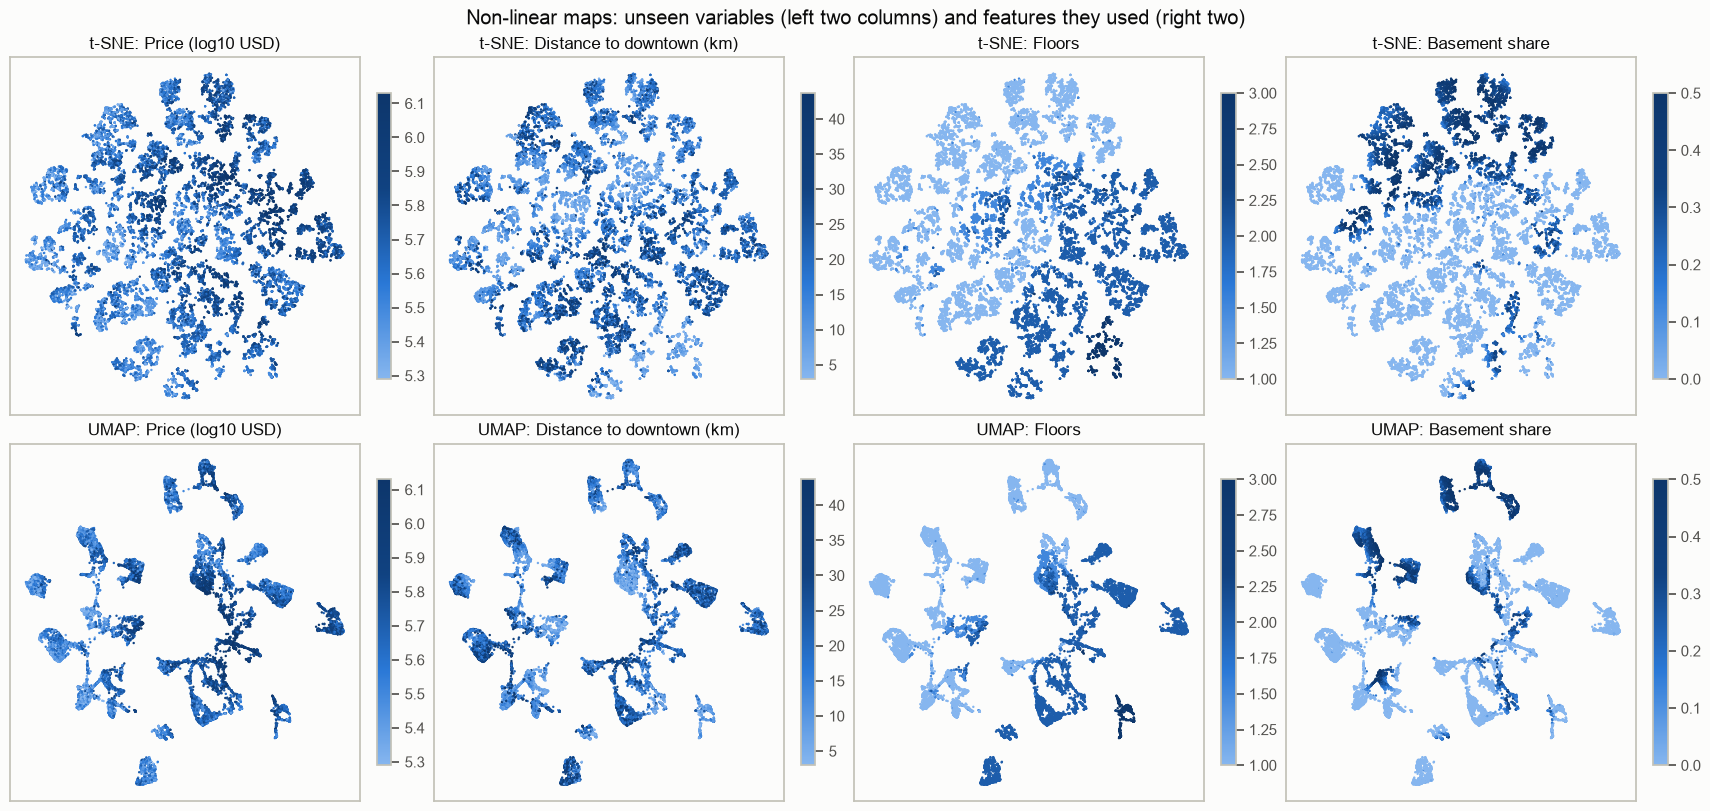

In [20]:
MAPS = {"t-SNE": tsne_xy, "UMAP": umap_xy}
COLOURS_USED = {"Floors": houses["floors"].to_numpy(), "Basement share": houses["basement_share"].to_numpy()}

fig, axes = plt.subplots(2, 4, figsize=(17, 8), constrained_layout=True)
for row, (method, xy) in zip(axes, MAPS.items()):
    for ax, (label, values) in zip(row, {**COLOURS, **COLOURS_USED}.items()):
        low, high = np.percentile(values, [2, 98])
        points = draw_map(ax, xy, values, f"{method}: {label}", "", "", low, high)
        ax.set(xticks=[], yticks=[])
        fig.colorbar(points, ax=ax, shrink=0.8)
fig.suptitle("Non-linear maps: unseen variables (left two columns) and features they used (right two)")
save_fig("04_tsne_umap_maps")
plt.show()

**What the t-SNE and UMAP maps show** (keeping in mind that the size of an island and the distance between islands mean nothing)

- **Both break the data into many islands.** That looks like strong structure, in contrast with the continuous PCA cloud. The right-hand columns give the first clue: most islands are uniform in `floors` and split sharply on whether `basement_share` is zero.
- **The unseen variables do vary between islands**: some are mostly cheap, others mostly expensive. In both maps there is no single smooth gradient across the whole picture, though, and we cannot read anything from the overall arrangement.
- **Similar stories in both methods:** UMAP gives fewer, more compact islands and t-SNE a more even spread. That difference comes from the methods, not from the houses.

The next cell tests the clue about the islands.

Reading colours by eye is not enough, so we measure it. For each house we find its nearest neighbour **on the map** and ask how often both share a value. "By chance" is what two random houses would give. If a column is close to 100% and far above chance, the islands are organised around that column.

In [21]:
map_neighbour = {
    method: NearestNeighbors(n_neighbors=2).fit(xy).kneighbors(xy, return_distance=False)[:, 1]
    for method, xy in MAPS.items()
}
discrete = pd.DataFrame({
    "floors": houses["floors"],
    "has_basement": houses["basement_share"] > 0,
    "bedrooms": houses["bedrooms"],
    "grade": houses["grade"],
    "condition (not used)": houses["condition"],
    "zipcode (not used)": houses["zipcode"],
})

island_check = pd.DataFrame({
    method: {col: (discrete[col].to_numpy() == discrete[col].to_numpy()[nearest]).mean() for col in discrete}
    for method, nearest in map_neighbour.items()
})
island_check["by chance"] = {col: (discrete[col].value_counts(normalize=True) ** 2).sum() for col in discrete}
island_check.round(3)

,t-SNE,UMAP,by chance
floors,0.985,0.952,0.397
has_basement,0.982,0.967,0.522
bedrooms,0.995,0.979,0.345
grade,0.981,0.925,0.292
condition (not used),0.586,0.586,0.498
zipcode (not used),0.141,0.096,0.017


**The islands are mostly a product of the discrete columns.** On the t-SNE map, a house and its nearest neighbour have the same number of bedrooms 99.5% of the time (34.5% by chance), the same floors 98.5% (39.7%), the same basement status 98.2% (52.2%) and the same grade 98.1% (29.2%). UMAP gives 92.5–97.9%.

Because these columns move in fixed steps, houses with the same combination of bedrooms, floors, grade and basement status stick together, and the methods draw each combination as a small island. So **most islands are combinations of categories, not distinct house types**, which is why the data looks continuous under PCA and fragmented here.

The columns the maps did not see barely behave like this: `condition` stays near chance (58.6% against 49.8%). `zipcode` is well above chance but low in absolute terms (14.1% and 9.6% against 1.7%), so physically similar houses are only sometimes in the same area.

**Consequences for the clustering:** density-based methods applied to these maps would mostly recover those combinations. Clusters must be fitted on the scaled features, and the maps used only to **show** the result.

How far can we trust these maps? **Trustworthiness** measures whether the neighbours on a 2D map are also neighbours in the 8 scaled dimensions (1 = perfect). It is measured on a random sample of 3,000 houses, because it compares all pairs. It only checks local neighbourhoods, so it says nothing about distances between far-apart groups.

In [22]:
sample = np.random.default_rng(RANDOM_STATE).choice(len(houses), size=3000, replace=False)
X_sample = X_scaled.to_numpy()[sample]

trust = pd.Series({
    method: trustworthiness(X_sample, xy[sample], n_neighbors=15)
    for method, xy in {"PCA": pca_xy, "t-SNE": tsne_xy, "UMAP": umap_xy}.items()
}, name="trustworthiness")
trust.round(3)

PCA     0.890
t-SNE   0.988
UMAP    0.987
Name: trustworthiness, dtype: float64

**Reading.** t-SNE (0.988) and UMAP (0.987) preserve local neighbourhoods better than the 2D PCA map (0.890), which is what they optimise. This confirms that close points really are similar houses, partly for the reason found above: neighbours share the same discrete values. It does **not** make the islands real groups. PCA remains the map whose axes and distances can be interpreted.

**Conclusion of section 2:** the housing stock has about 3–4 real dimensions: *how much house*, *building form*, and *plot / suburban position*, with a weaker fourth on rooms. The data looks more like a continuum with denser areas and one small, distinctive tail than like clear separate types.

## 2.7 Keeping the coordinates

Every map becomes columns of the final dataset, in the same row order as `houses`. They are stored in a separate table so that sections 3 to 7 can use them without recomputing, and without changing `houses` by accident.

In [23]:
map_coordinates = pd.DataFrame(np.hstack([pca_xy, tsne_xy, umap_xy]), index=houses.index,
                               columns=["pca_x", "pca_y", "tsne_x", "tsne_y", "umap_x", "umap_y"])
assert len(map_coordinates) == len(houses) and map_coordinates.notna().all().all()
print(map_coordinates.shape)
map_coordinates.head(3)

(20555, 6)


,pca_x,pca_y,tsne_x,tsne_y,umap_x,umap_y
0,-2.279,-0.440,-84.054,40.100,-7.014,10.508
1,0.106,-0.089,-21.360,25.368,0.859,7.271
2,-3.820,-0.593,-97.322,-10.761,-3.785,1.759


**What sections 0–2 leave ready for the next sections**

| Object | Content |
|---|---|
| `houses` | 20,555 houses (one row = one house): cleaned columns plus engineered features, the base of the final dataset |
| `CLUSTER_FEATURES`, `ASIDE_FEATURES` | The 8 columns clustered on, and the 14 kept for interpretation |
| `X` | The 8 features in original units: the input of `preprocess` and of the final saved pipeline |
| `X_scaled` | The fitted result of `preprocess` (log10 + scaling): the matrix to cluster on |
| `preprocess` | The fitted `Pipeline`, to be extended with the clustering model |
| `map_coordinates` | `pca_x`, `pca_y`, `tsne_x`, `tsne_y`, `umap_x`, `umap_y`, aligned row by row with `houses` |

Figures `00` to `04` are in `figures/`; later sections can continue from `05`.